# FSI visualization

Set `SIMULATIONS` to one or more case names saved under `code/cases/outputs/<name>/<name>.npz`, or pass explicit `.npz` paths. The final-state cells plot pressure-cell-centered fluid velocity, the deformed solid, and fluid vorticity.

The frame and video cells are disabled by default. Set `MAKE_STATE_FRAMES = True` to write PNG states, then `MAKE_VIDEO = True` to assemble them with `ffmpeg`.

In [1]:
from pathlib import Path
import re
import shutil
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection


def find_project_root(start=Path.cwd()):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "code" / "immersed_fsi").is_dir():
            return candidate
    raise RuntimeError("Could not find the project root containing code/immersed_fsi.")


PROJECT_ROOT = find_project_root()
CODE_DIR = PROJECT_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from immersed_fsi.fluid import cell_centered_velocity, cell_centered_vorticity
from immersed_fsi.geometry import point_matrix, quadrilateral_connectivity, triangle_connectivity
from immersed_fsi.io import load_results, parse_float, parse_int


# Names such as "falling_square" or "falling_cylinder", or explicit .npz paths.
SIMULATIONS = ["falling_square"]

OUTPUT_ROOT = CODE_DIR / "cases" / "outputs"
FIGURE_ROOT = CODE_DIR / "plots" / "figures"
STATE_ROOT = CODE_DIR / "plots" / "states"
VIDEO_ROOT = CODE_DIR / "plots" / "videos"

# Set to None for an automatic stride based on grid size.
QUIVER_STRIDE = None
SOLID_FACECOLOR = "#f2a65a"
SOLID_EDGECOLOR = "black"
SOLID_ALPHA = 0.62

# Fixed figure geometry for videos. Keep these constant frame to frame so
# changing colorbar tick labels do not move the images around.
FIGURE_SIZE = (14, 5)
AX_VELOCITY_POS = [0.055, 0.145, 0.365, 0.73]
CAX_VELOCITY_POS = [0.435, 0.145, 0.018, 0.73]
AX_VORTICITY_POS = [0.545, 0.145, 0.365, 0.73]
CAX_VORTICITY_POS = [0.925, 0.145, 0.018, 0.73]

FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
STATE_ROOT.mkdir(parents=True, exist_ok=True)
VIDEO_ROOT.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT

PosixPath('/Users/gabrielemarchi/Desktop/FSI')

In [2]:
def safe_name(value):
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_")
    return text or "simulation"


def resolve_result(spec):
    spec_text = str(spec)
    path = Path(spec_text).expanduser()
    candidates = []

    if path.suffix == ".npz":
        candidates.append(path if path.is_absolute() else PROJECT_ROOT / path)
        candidates.append(path if path.is_absolute() else CODE_DIR / path)

    for base in (Path.cwd(), PROJECT_ROOT, CODE_DIR):
        candidate = path if path.is_absolute() else base / path
        if candidate.is_dir():
            candidates.extend(sorted(candidate.glob("*.npz")))
        else:
            candidates.append(candidate)

    name = spec_text.rstrip("/")
    candidates.append(OUTPUT_ROOT / name / f"{name}.npz")
    output_folder = OUTPUT_ROOT / name
    if output_folder.is_dir():
        candidates.extend(sorted(output_folder.glob("*.npz")))

    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if candidate.is_file() and candidate.suffix == ".npz":
            return candidate

    raise FileNotFoundError(f"Could not resolve simulation {spec!r} under {OUTPUT_ROOT}.")


def load_case(spec):
    npz_path = resolve_result(spec)
    loaded = load_results(npz_path)
    name = loaded.params.get("case_name") or npz_path.stem
    return {
        "spec": spec,
        "name": name,
        "path": npz_path,
        "params": loaded.params,
        "arrays": loaded.arrays,
    }


def selected_cases(cases, specs):
    if specs is None:
        return list(cases)
    if isinstance(specs, (str, Path)):
        specs = [specs]
    wanted = {str(spec) for spec in specs}
    selected = []
    for case in cases:
        aliases = {
            str(case["spec"]),
            str(case["name"]),
            case["path"].stem,
            str(case["path"]),
        }
        if aliases & wanted:
            selected.append(case)
    if not selected:
        raise ValueError(f"No loaded simulations match {specs!r}.")
    return selected


def array_at_frame(case, base_name, frame=-1):
    arrays = case["arrays"]
    final_name = f"{base_name}_final"
    if frame in (-1, None, "final") and final_name in arrays:
        return np.asarray(arrays[final_name])
    if base_name in arrays:
        values = np.asarray(arrays[base_name])
        if values.ndim >= 3:
            return values[frame]
        if base_name in {"u_s", "v_s", "a_s"} and values.ndim == 2:
            return values[frame]
        return values
    if final_name in arrays:
        return np.asarray(arrays[final_name])
    raise KeyError(f"{case['name']} is missing {base_name!r} or {final_name!r}.")


def history_length(case):
    arrays = case["arrays"]
    lengths = []
    for key in ("u_f", "v_f", "p_f"):
        if key in arrays and np.asarray(arrays[key]).ndim >= 3:
            lengths.append(np.asarray(arrays[key]).shape[0])
    for key in ("u_s", "v_s", "a_s"):
        if key in arrays and np.asarray(arrays[key]).ndim == 2:
            lengths.append(np.asarray(arrays[key]).shape[0])
    return min(lengths) if lengths else 1


def frame_indices(case, stride=1, max_frames=None):
    n_frames = history_length(case)
    if n_frames <= 1:
        return [-1]
    stride = max(1, int(stride))
    frames = list(range(0, n_frames, stride))
    if frames[-1] != n_frames - 1:
        frames.append(n_frames - 1)
    if max_frames is not None and len(frames) > max_frames:
        picks = np.linspace(0, len(frames) - 1, int(max_frames)).round().astype(int)
        frames = [frames[i] for i in np.unique(picks)]
    return frames


def fluid_metadata(case):
    params = case["params"]
    u = array_at_frame(case, "u_f", frame=-1)
    fallback_ny = u.shape[0] - 2
    fallback_nx = u.shape[1] - 2
    nx = parse_int(params, "fluid_nx", parse_int(params, "nx_f", fallback_nx))
    ny = parse_int(params, "fluid_ny", parse_int(params, "ny_f", fallback_ny))
    dx = parse_float(params, "fluid_dx", parse_float(params, "dx_f", 1.0 / nx))
    dy = parse_float(params, "fluid_dy", parse_float(params, "dy_f", 1.0 / ny))
    lx = parse_float(params, "fluid_lx", parse_float(params, "lx_f", nx * dx))
    ly = parse_float(params, "fluid_ly", parse_float(params, "ly_f", ny * dy))
    return {"nx": nx, "ny": ny, "dx": dx, "dy": dy, "lx": lx, "ly": ly}


def pressure_cell_grid(meta):
    x = (np.arange(meta["nx"]) + 0.5) * meta["dx"]
    y = (np.arange(meta["ny"]) + 0.5) * meta["dy"]
    return np.meshgrid(x, y, indexing="xy")


def solid_positions(case, frame=-1):
    arrays = case["arrays"]
    if "P_physical" in arrays:
        P = point_matrix(arrays["P_physical"], copy=True)
    else:
        P = point_matrix(arrays["P"], copy=True)
        if "d0_x_s" in arrays and "d0_y_s" in arrays:
            P = P + np.vstack((arrays["d0_x_s"], arrays["d0_y_s"]))

    try:
        u_s = np.asarray(array_at_frame(case, "u_s", frame=frame), dtype=float).reshape(-1)
    except KeyError:
        return P

    nb = P.shape[1]
    if u_s.size != 2 * nb:
        return P
    return P + np.vstack((u_s[:nb], u_s[nb:]))


def solid_polygons(case, frame=-1):
    P = solid_positions(case, frame=frame)
    T = case["arrays"]["T"]
    try:
        elements = triangle_connectivity(T)
    except ValueError:
        elements = quadrilateral_connectivity(T)
    return [P[:, element].T for element in elements]


def add_solid(ax, case, frame=-1):
    collection = PolyCollection(
        solid_polygons(case, frame=frame),
        facecolor=SOLID_FACECOLOR,
        edgecolor=SOLID_EDGECOLOR,
        linewidth=0.55,
        alpha=SOLID_ALPHA,
        zorder=5,
    )
    ax.add_collection(collection)
    return collection


def quiver_stride(meta, requested):
    if requested is not None:
        return max(1, int(requested))
    return max(1, int(max(meta["nx"], meta["ny"]) / 42))

In [3]:
cases = [load_case(spec) for spec in SIMULATIONS]
for case in cases:
    meta = fluid_metadata(case)
    print(
        f"{case['name']}: {case['path']} | "
        f"fluid {meta['nx']}x{meta['ny']} | saved frames {history_length(case)}"
    )

falling_square: /Users/gabrielemarchi/Desktop/FSI/code/cases/outputs/falling_square/falling_square.npz | fluid 100x100 | saved frames 2001


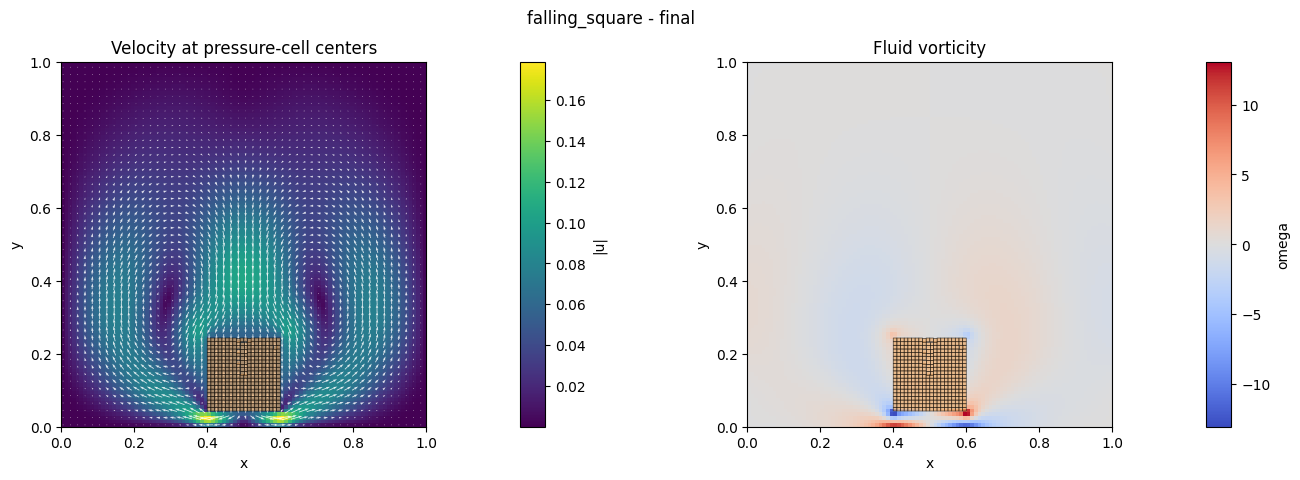

In [4]:
def plot_case_state(case, frame=-1):
    meta = fluid_metadata(case)
    u_f = array_at_frame(case, "u_f", frame=frame)
    v_f = array_at_frame(case, "v_f", frame=frame)
    uc, vc = cell_centered_velocity(u_f, v_f)
    vorticity = cell_centered_vorticity(u_f, v_f, meta["dx"], meta["dy"])
    speed = np.sqrt(uc * uc + vc * vc)
    X, Y = pressure_cell_grid(meta)
    stride = quiver_stride(meta, QUIVER_STRIDE)
    skip = (slice(None, None, stride), slice(None, None, stride))

    fig = plt.figure(figsize=FIGURE_SIZE)
    axes = [fig.add_axes(AX_VELOCITY_POS), fig.add_axes(AX_VORTICITY_POS)]
    cax0 = fig.add_axes(CAX_VELOCITY_POS)
    cax1 = fig.add_axes(CAX_VORTICITY_POS)
    extent = [0.0, meta["lx"], 0.0, meta["ly"]]

    im0 = axes[0].imshow(speed, origin="lower", extent=extent, cmap="viridis")
    axes[0].quiver(
        X[skip],
        Y[skip],
        uc[skip],
        vc[skip],
        color="white",
        alpha=0.85,
        width=0.0022,
        pivot="mid",
    )
    add_solid(axes[0], case, frame=frame)
    axes[0].set_title("Velocity at pressure-cell centers")
    fig.colorbar(im0, cax=cax0, label="|u|")

    vmax = float(np.nanmax(np.abs(vorticity))) if vorticity.size else 1.0
    vmax = vmax if np.isfinite(vmax) and vmax > 0.0 else 1.0
    im1 = axes[1].imshow(
        vorticity,
        origin="lower",
        extent=extent,
        cmap="coolwarm",
        vmin=-vmax,
        vmax=vmax,
    )
    add_solid(axes[1], case, frame=frame)
    axes[1].set_title("Fluid vorticity")
    fig.colorbar(im1, cax=cax1, label="omega")

    frame_label = "final" if frame == -1 else f"frame {frame}"
    fig.suptitle(f"{case['name']} - {frame_label}")
    for ax in axes:
        ax.set_xlim(0.0, meta["lx"])
        ax.set_ylim(0.0, meta["ly"])
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    return fig


for case in cases:
    fig = plot_case_state(case, frame=-1)
    plt.show()

## Optional video workflow

The next cell writes one PNG per saved state into `code/plots/states/<simulation>/`. If a result was saved with final-state arrays only, the folder will contain only one frame. For a real video, run the simulation with saved histories, for example by using `output.save_mode: history` or `both` and a reasonable `time.history_stride`.

In [7]:
MAKE_STATE_FRAMES = True
FRAME_SIMULATIONS = SIMULATIONS
FRAME_STRIDE = 10
MAX_FRAMES = None
FRAME_DPI = 150
CLEAR_STATE_FOLDER = True


if MAKE_STATE_FRAMES:
    for case in selected_cases(cases, FRAME_SIMULATIONS):
        folder = STATE_ROOT / safe_name(case["name"])
        if CLEAR_STATE_FOLDER and folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)

        frames = frame_indices(case, stride=FRAME_STRIDE, max_frames=MAX_FRAMES)
        if frames == [-1]:
            print(f"{case['name']}: only final-state arrays found; writing one frame.")

        for out_index, frame in enumerate(frames):
            fig = plot_case_state(case, frame=frame)
            fig.savefig(folder / f"frame_{out_index:05d}.png", dpi=FRAME_DPI)
            plt.close(fig)

        print(f"{case['name']}: wrote {len(frames)} frame(s) to {folder}")
else:
    print("MAKE_STATE_FRAMES is False. Set it to True to write PNG states.")

/Users/gabrielemarchi/env/lib/python3.13/site-packages/matplotlib/quiver.py:695: RuntimeWarning: divide by zero encountered in scalar divide
  length = a * (widthu_per_lenu / (self.scale * self.width))
/Users/gabrielemarchi/env/lib/python3.13/site-packages/matplotlib/quiver.py:695: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


falling_square: wrote 201 frame(s) to /Users/gabrielemarchi/Desktop/FSI/code/plots/states/falling_square


In [8]:
MAKE_VIDEO = True
VIDEO_SIMULATIONS = SIMULATIONS
VIDEO_FPS = 24


if MAKE_VIDEO:
    for case in selected_cases(cases, VIDEO_SIMULATIONS):
        frame_folder = STATE_ROOT / safe_name(case["name"])
        if not any(frame_folder.glob("frame_*.png")):
            raise FileNotFoundError(
                f"No frames found in {frame_folder}. Run the state-frame cell first."
            )

        output = VIDEO_ROOT / f"{safe_name(case['name'])}.mp4"
        cmd = [
            "ffmpeg",
            "-y",
            "-framerate",
            str(VIDEO_FPS),
            "-i",
            str(frame_folder / "frame_%05d.png"),
            "-pix_fmt",
            "yuv420p",
            "-vf",
            "pad=ceil(iw/2)*2:ceil(ih/2)*2",
            str(output),
        ]
        print("$ " + " ".join(cmd))
        subprocess.run(cmd, check=True)
        print(f"Wrote {output}")
else:
    print("MAKE_VIDEO is False. Set it to True after generating PNG states.")

$ ffmpeg -y -framerate 24 -i /Users/gabrielemarchi/Desktop/FSI/code/plots/states/falling_square/frame_%05d.png -pix_fmt yuv420p -vf pad=ceil(iw/2)*2:ceil(ih/2)*2 /Users/gabrielemarchi/Desktop/FSI/code/plots/videos/falling_square.mp4


ffmpeg version 7.1.1 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex

Wrote /Users/gabrielemarchi/Desktop/FSI/code/plots/videos/falling_square.mp4


[out#0/mp4 @ 0x157906710] video:1308KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.236655%
frame=  201 fps=0.0 q=-1.0 Lsize=    1311KiB time=00:00:08.29 bitrate=1295.0kbits/s speed=16.4x    
[libx264 @ 0x1579082a0] frame I:1     Avg QP:22.19  size: 30304
[libx264 @ 0x1579082a0] frame P:80    Avg QP:21.04  size: 13557
[libx264 @ 0x1579082a0] frame B:120   Avg QP:25.86  size:  1863
[libx264 @ 0x1579082a0] consecutive B-frames: 12.4% 19.9% 11.9% 55.7%
[libx264 @ 0x1579082a0] mb I  I16..4: 20.5% 70.9%  8.6%
[libx264 @ 0x1579082a0] mb P  I16..4:  0.7%  1.1%  0.4%  P16..4: 14.5%  2.3%  2.8%  0.0%  0.0%    skip:78.3%
[libx264 @ 0x1579082a0] mb B  I16..4:  0.2%  0.2%  0.1%  B16..8:  8.4%  0.7%  0.1%  direct: 1.0%  skip:89.2%  L0:36.3% L1:59.7% BI: 4.0%
[libx264 @ 0x1579082a0] 8x8 transform intra:53.7% inter:45.0%
[libx264 @ 0x1579082a0] coded y,uvDC,uvAC intra: 13.1% 18.1% 6.5% inter: 4.5% 6.5% 1.3%
[libx264 @ 0x1579082a0] i16 v,h,dc,p: 75% 17%  4%  4%
[